# Clustering
## Step 00: Load dataset

In [1]:
import pandas as pd

df = pd.read_csv("df_prepared.csv")

print("Shape:", df.shape)
df.info()
df.head()

Shape: (21616, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21616 entries, 0 to 21615
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BGGId                   21616 non-null  int64  
 1   YearPublished           21616 non-null  int64  
 2   GameWeight              21616 non-null  float64
 3   MinPlayers              21616 non-null  int64  
 4   MaxPlayers              21616 non-null  int64  
 5   ComAgeRec               21616 non-null  float64
 6   NumOwned                21616 non-null  int64  
 7   ComMinPlaytime          21616 non-null  float64
 8   ComMaxPlaytime          21616 non-null  float64
 9   MfgAgeRec               21616 non-null  int64  
 10  NumUserRatings          21616 non-null  int64  
 11  NumAlternates           21616 non-null  int64  
 12  NumExpansions           21616 non-null  int64  
 13  NumImplementations      21616 non-null  int64  
 14  IsReimplementation 

,BGGId,YearPublished,GameWeight,MinPlayers,MaxPlayers,ComAgeRec,NumOwned,ComMinPlaytime,ComMaxPlaytime,MfgAgeRec,...,Cat:Party,Cat:Childrens,Rating,NumInterest,NumOwned_log,NumUserRatings_log,NumAlternates_log,NumExpansions_log,NumImplementations_log,NumInterest_log
0,17755,1900,1.0000,2,6,4.000000,145,20.0,20.0,7,...,0,1,Low,2,4.983607,3.713572,2.944439,0.000000,1.098612,1.098612
1,14765,1900,2.6000,4,4,11.560535,25,10.0,10.0,8,...,0,0,High,10,3.258097,3.637586,0.000000,0.000000,0.000000,2.397895
2,17183,1900,2.0000,2,4,10.000000,20,60.0,60.0,12,...,0,0,Medium,1,3.044522,3.526361,2.302585,0.000000,0.000000,0.693147
3,2294,1903,1.1379,1,8,7.333333,1848,20.0,20.0,7,...,0,0,Low,22,7.522400,6.073045,1.098612,0.000000,0.000000,3.135494
4,140,1903,1.1582,3,8,7.842105,15115,30.0,90.0,7,...,1,0,Medium,623,9.623509,9.053920,2.995732,0.693147,0.693147,6.436150


## Step 01: Select features for clustering (choose attributes)
Using all numeric + binary category features allows the algorithm to:
- capture game mechanics
- include theme categories
- incorporate popularity trends
- group based on multiple dimensions instead of one dominant factor

In [2]:
# defining cluster feature set
features = [
    "YearPublished", "GameWeight", "MinPlayers", "MaxPlayers",
    "ComAgeRec", "MfgAgeRec", "NumOwned_log", "NumInterest_log",
    "NumUserRatings_log", "NumAlternates_log", "NumExpansions_log",
    "NumImplementations_log", "Cat:Thematic", "Cat:Strategy",
    "Cat:War", "Cat:Family", "Cat:CGS", "Cat:Abstract",
    "Cat:Party", "Cat:Childrens", "Kickstarted", "IsReimplementation"
]

X = df[features]

print("Selected features:", len(features))
X.head()

Selected features: 22


,YearPublished,GameWeight,MinPlayers,MaxPlayers,ComAgeRec,MfgAgeRec,NumOwned_log,NumInterest_log,NumUserRatings_log,NumAlternates_log,...,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Kickstarted,IsReimplementation
0,1900,1.0000,2,6,4.000000,7,4.983607,1.098612,3.713572,2.944439,...,0,0,0,0,0,0,0,1,0,1
1,1900,2.6000,4,4,11.560535,8,3.258097,2.397895,3.637586,0.000000,...,0,0,0,0,0,0,0,0,0,0
2,1900,2.0000,2,4,10.000000,12,3.044522,0.693147,3.526361,2.302585,...,0,0,0,0,0,0,0,0,0,0
3,1903,1.1379,1,8,7.333333,7,7.522400,3.135494,6.073045,1.098612,...,0,0,0,1,0,0,0,0,0,0
4,1903,1.1582,3,8,7.842105,7,9.623509,6.436150,9.053920,2.995732,...,0,0,0,1,0,0,1,0,0,1


## Step 02: Standardize Features
Why? Because K-Means relies on Euclidean distance, and without scaling:
- features with large numeric ranges (e.g., NumOwned_log) would dominate
- categorical binaries (0/1) would have almost no influence
- clusters would be distorted and meaningless

Standardization ensures every feature contributes equally by transforming them to:
- mean = 0
- standard deviation = 1

This is required before running K-Means, DBSCAN, or hierarchical clustering

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)
print("Mean of first 5 features:", X_scaled.mean(axis=0)[:5])
print("Std of first 5 features:", X_scaled.std(axis=0)[:5])

Scaled shape: (21616, 22)
Mean of first 5 features: [-4.37580723e-15  5.91680664e-17  1.05187674e-17  9.20392145e-18
 -6.31126042e-17]
Std of first 5 features: [1. 1. 1. 1. 1.]


### 1. K-Means

#### Evaluate K-Means for K = 2 to 10

K-Means is mandatory in project requirements. We must justify the choice of K. We use:
- Inertia (Elbow method): measures within-cluster compactness
- Silhouette Score: measures cluster separation quality

This ensures we don’t guess K

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    inertia = kmeans.inertia_
    sil = silhouette_score(X_scaled, labels)
    
    results.append((k, inertia, sil))

df_k = pd.DataFrame(results, columns=["K", "Inertia", "Silhouette"])
print(df_k)

    K        Inertia  Silhouette
0   2  416080.584060    0.207106
1   3  381732.124329    0.141092
2   4  358524.765093    0.158209
3   5  338396.065789    0.160262
4   6  317932.293429    0.193396
5   7  295026.905615    0.184707
6   8  277026.219877    0.193597
7   9  260220.552185    0.204794
8  10  246163.842424    0.207818


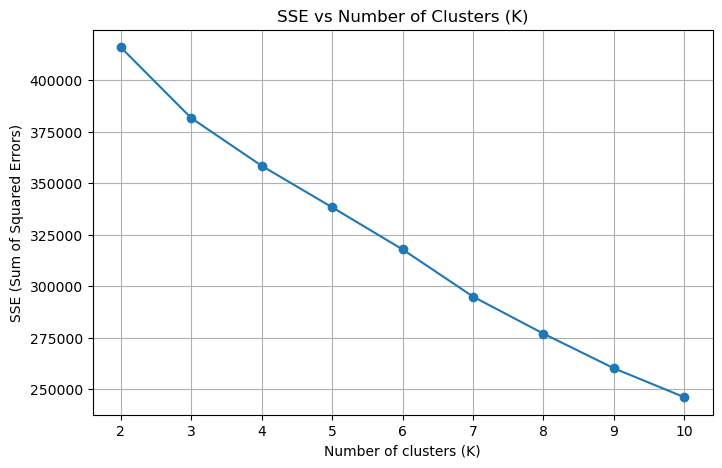

In [5]:
results_df = pd.DataFrame(results, columns=["K", "Inertia", "Silhouette"])

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(results_df["K"], results_df["Inertia"], marker='o')
plt.title("SSE vs Number of Clusters (K)")
plt.xlabel("Number of clusters (K)")
plt.ylabel("SSE (Sum of Squared Errors)")
plt.grid(True)
plt.show()

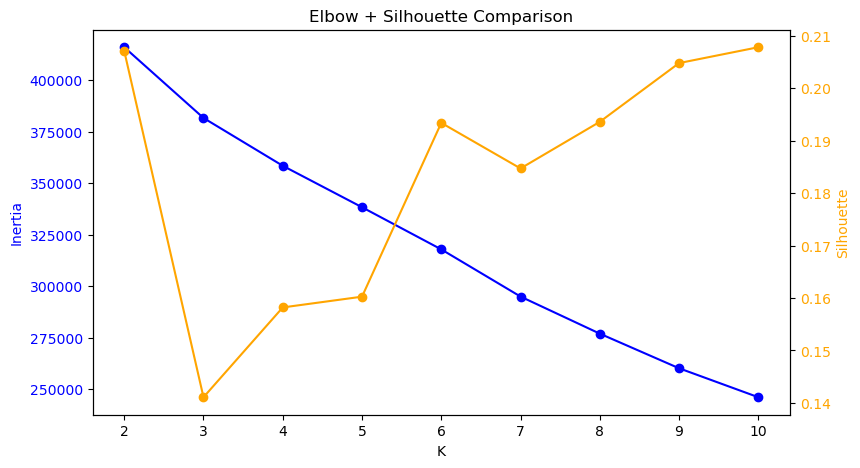

In [6]:
fig, ax1 = plt.subplots(figsize=(9,5))

ax1.set_xlabel("K")
ax1.set_ylabel("Inertia", color='blue')
ax1.plot(df_k["K"], df_k["Inertia"], marker='o', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.set_ylabel("Silhouette", color='orange')
ax2.plot(df_k["K"], df_k["Silhouette"], marker='o', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

plt.title("Elbow + Silhouette Comparison")
plt.show()

**K = 6 is selected as the optimal number of clusters because it achieves the best balance between compactness and separation, supported by both inertia flattening and a high silhouette score, while maintaining practical and interpretable cluster size.**

#### Fit the Final K-Means Model (K = 6)

In [7]:
from sklearn.cluster import KMeans

k_opt = 6

kmeans_final = KMeans(
    n_clusters=k_opt,
    random_state=42,
    n_init=10
)

labels_k6 = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to df
df["Cluster_K6"] = labels_k6

df["Cluster_K6"].value_counts()

Cluster_K6
2    11005
3     3473
1     3466
4     2040
0     1008
5      624
Name: count, dtype: int64

**Most clusters are well populated. Only one is small (Cluster 5 = 3%) but still acceptable. No clusters are tiny (<1%), so K=6 remains justified. The resulting clusters show a balanced distribution, with the majority of games assigned across five sizable groups and only one smaller niche cluster, indicating that K=6 provides meaningful segmentation without producing excessively small clusters.**

#### Extract Cluster Centroids

In [8]:
import pandas as pd

centroids_scaled = kmeans_final.cluster_centers_

centroids_original = pd.DataFrame(
    scaler.inverse_transform(centroids_scaled),
    columns=features
)

centroids_original.round(2)

,YearPublished,GameWeight,MinPlayers,MaxPlayers,ComAgeRec,MfgAgeRec,NumOwned_log,NumInterest_log,NumUserRatings_log,NumAlternates_log,...,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Kickstarted,IsReimplementation
0,1998.42,1.93,1.94,3.42,8.47,7.93,5.67,3.88,5.07,0.59,...,0.00,0.04,0.01,0.09,0.00,1.00,0.0,0.02,0.06,0.09
1,2011.97,2.70,1.81,4.64,11.39,11.98,7.54,6.05,6.84,0.64,...,0.27,0.51,0.05,0.01,0.04,0.00,0.0,0.00,0.34,0.19
2,2008.97,1.58,2.10,6.46,8.83,9.00,5.30,3.23,4.45,0.39,...,0.01,0.00,0.00,0.00,0.01,-0.00,-0.0,0.06,0.15,0.09
3,1998.77,2.89,1.79,3.32,13.76,10.21,5.81,3.95,4.61,0.18,...,0.02,0.02,0.95,0.00,0.00,-0.00,0.0,0.00,0.04,0.12
4,2006.12,1.67,2.01,5.22,8.13,8.97,7.45,5.31,6.88,1.07,...,0.05,0.18,0.00,0.97,0.00,0.01,0.0,0.08,0.11,0.18
5,2007.54,1.34,2.81,11.77,9.60,10.20,7.49,4.97,6.82,1.14,...,0.06,0.01,0.00,0.24,0.00,0.00,1.0,0.01,0.13,0.15


**Interpretations**
<br>
Cluster 2 (Largest 51%)
- Year = 2009
- GameWeight = 1.6 (light/medium)
- MinPlayers = 2, Max = 6
- Low category flags
- Low-moderate engagement (NumOwned_log = 5.3)

Mainstream modern family-friendly games, medium popularity.
<br>

Cluster 3 (16%)
- Year = 1999
- GameWeight = 2.9 (high complexity)
- ComAgeRec = 13+
- Cat:War = 0.95
- Very low expansions & ratings

Heavy war & strategy games, older niche audience.
<br>

Cluster 1 (16%)
- Year = 2012 (newest)
- GameWeight ≈ 2.7
- Very high popularity (NumOwned_log = 7.5, NumInterest = 6.0)
- High Strategy + Thematic categories

Highly popular modern strategy games, major releases.
<br>

Cluster 4 (9%)
- MaxPlayers ≈ 5
- Cat:Family ≈ 0.97
- Moderate interest & ownership

Family-oriented games, accessible and social.
<br>

Cluster 0 (5%)
- GameWeight = 1.9
- Low popularity
- Cat:Abstract = 1.0

Abstract / minimalist low-engagement games.
<br>

Cluster 5 (3%)
- MaxPlayers = 12 (party-scale)
- Cat:Party = 1.0
- High popularity

Large-group party games, strong community appeal.

#### Silhouette Score for Final Model

In [9]:
from sklearn.metrics import silhouette_score

sil_final = silhouette_score(X_scaled, labels_k6)
sil_final

0.19339618625281488

**For high-dimensional real-world datasets, values between 0.15–0.25 are common. Indicates reasonable but not perfect separation. The final silhouette score of 0.193 suggests a moderate level of cohesion and separation, which is typical for large real datasets with mixed attributes, confirming that the K=6 model is appropriate and not over-segmented.**

#### Boxplots
how each numeric feature is distributed inside each cluster

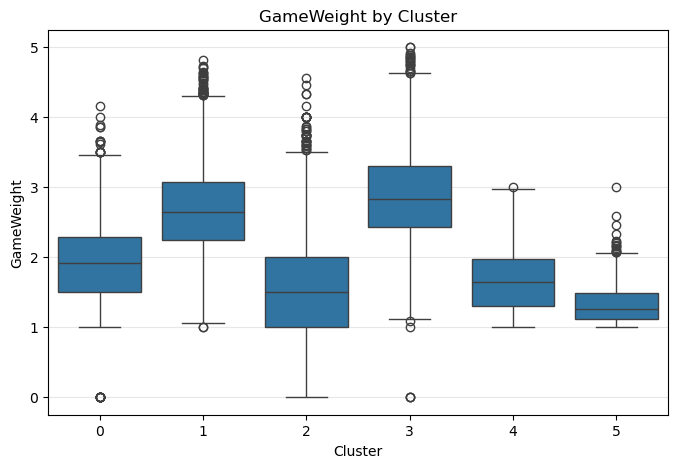

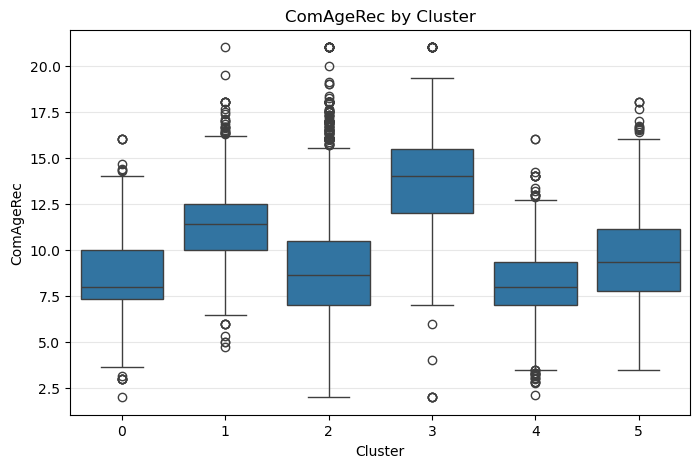

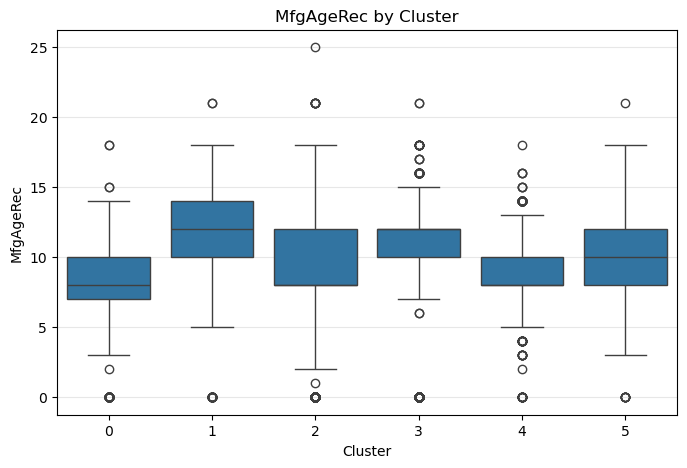

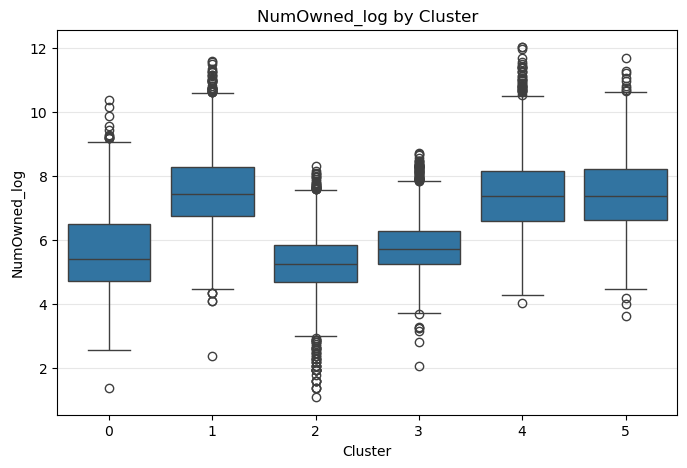

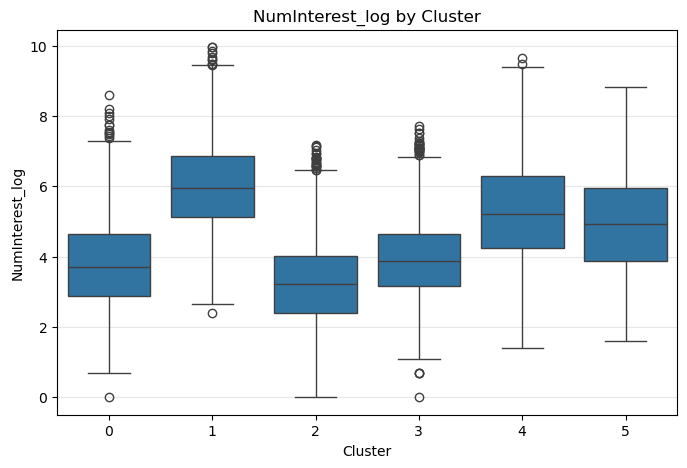

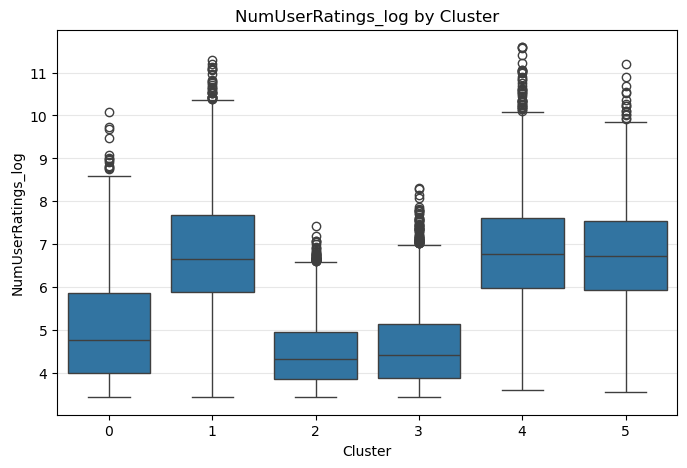

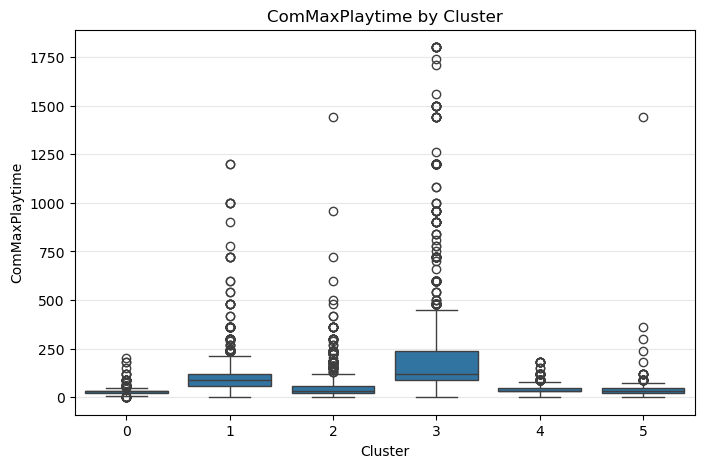

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_for_box = [
    "GameWeight",
    "ComAgeRec",
    "MfgAgeRec",
    "NumOwned_log",
    "NumInterest_log",
    "NumUserRatings_log",
    "ComMaxPlaytime"
]

for col in numeric_for_box:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="Cluster_K6", y=col)
    plt.title(f"{col} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(col)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

#### Category frequency heatmap
taking the mean per cluster gives you the proportion of games in the category

            Cat:Thematic  Cat:Strategy  Cat:War  Cat:Family  Cat:CGS  \
Cluster_K6                                                             
0                    0.2           4.2      1.3         9.2      0.2   
1                   26.6          51.5      5.4         0.5      4.0   
2                    0.7           0.5      0.2         0.5      1.3   
3                    2.2           1.9     95.0         0.0      0.4   
4                    5.0          17.5      0.3        96.6      0.0   
5                    6.1           1.4      0.2        24.4      0.0   

            Cat:Abstract  Cat:Party  Cat:Childrens  
Cluster_K6                                          
0                  100.0        0.0            2.2  
1                    0.1        0.0            0.0  
2                    0.0        0.0            6.0  
3                    0.0        0.0            0.1  
4                    0.9        0.0            8.0  
5                    0.2      100.0            1.1  

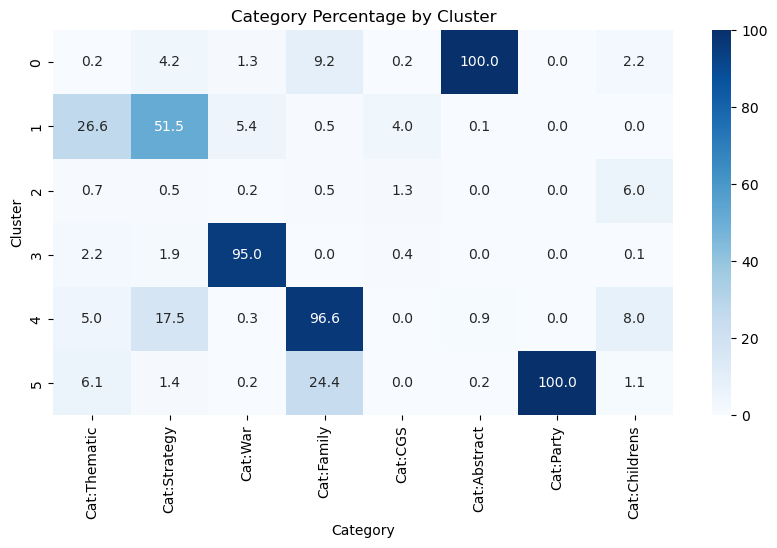

In [11]:
import numpy as np

cat_cols = [
    "Cat:Thematic",
    "Cat:Strategy",
    "Cat:War",
    "Cat:Family",
    "Cat:CGS",
    "Cat:Abstract",
    "Cat:Party",
    "Cat:Childrens"
]

cluster_cat = df.groupby("Cluster_K6")[cat_cols].mean() * 100  # in %
print(cluster_cat.round(1))

plt.figure(figsize=(10, 5))
sns.heatmap(cluster_cat.round(1), annot=True, fmt=".1f", cmap="Blues")
plt.title("Category Percentage by Cluster")
plt.xlabel("Category")
plt.ylabel("Cluster")
plt.show()

#### Radar charts
show overall profiles for clusters on a few key dimensions at once

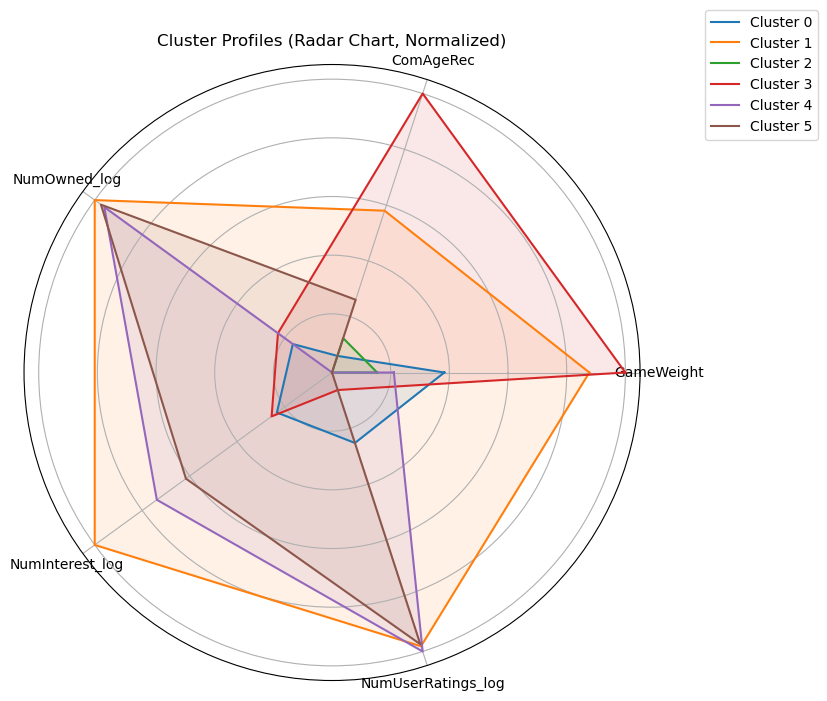

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1) Choose key features for radar that ARE in `features`
radar_features = [
    "GameWeight",
    "ComAgeRec",
    "NumOwned_log",
    "NumInterest_log",
    "NumUserRatings_log"
]

# 2) Recompute centroids in original units (just to be sure)
centroids_scaled = kmeans_final.cluster_centers_
centroids_original = pd.DataFrame(
    scaler.inverse_transform(centroids_scaled),
    columns=features
)

# 3) Subset to the radar features
centroids_radar = centroids_original[radar_features].copy()

# 4) Min-max normalize each feature to [0, 1] for visualization
centroids_norm = (centroids_radar - centroids_radar.min()) / (
    centroids_radar.max() - centroids_radar.min()
)

# 5) Radar plot
labels = radar_features
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False)
angles = np.concatenate((angles, [angles[0]]))  # close the loop

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

for cluster_id in range(centroids_norm.shape[0]):
    values = centroids_norm.iloc[cluster_id].values
    values = np.concatenate((values, [values[0]]))  # close the polygon
    
    ax.plot(angles, values, label=f"Cluster {cluster_id}")
    ax.fill(angles, values, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
ax.set_yticklabels([])

plt.title("Cluster Profiles (Radar Chart, Normalized)")
plt.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.show()

**These features were chosen because they capture core aspects of gameplay difficulty and community attention, and they were all included in the clustering feature set.**

#### PCA plot (post-clustering)

Per notes, professor says: cluster BEFORE PCA. Now, we can use PCA only to project to 2D for visualization.

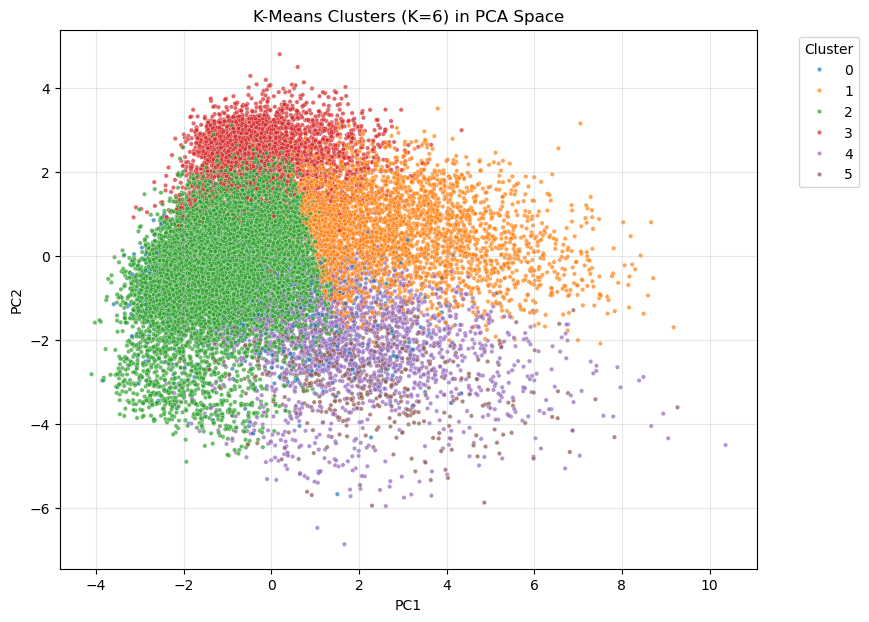

Explained variance by PC1 and PC2: [0.184 0.121]


In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df,
    x="PC1",
    y="PC2",
    hue="Cluster_K6",
    palette="tab10",
    s=10,
    alpha=0.7
)
plt.title("K-Means Clusters (K=6) in PCA Space")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

print("Explained variance by PC1 and PC2:",
      pca.explained_variance_ratio_.round(3))

**The PCA visualization shows partial but not complete separation between clusters, which is expected given dimensionality reduction from 22 to 2 components.**

#### IMPORTANT NOTE ABOUT RATINGS
Clustering was performed unsupervised using intrinsic game characteristics, excluding the rating variable (Week 6 Slides on page 4 says that cluster analysis DOES NOT inlcude supervised classification, and rating is considered a label even though it is categorial). The rating will be used exclusively in a post-clustering analysis to interpret the identified groups, as shown below. In particular, we examine how the distributions of low, medium, and high ratings vary across clusters, and whether the latent structure identified by K-Means aligns with the rating outcomes.

## Post-Clustering
This part is to analyze the question: how are Low / Medium / High rated games distributed across clusters? It allows us to see whether certain clusters are dominated by highly rated games or contain mostly low-rated ones.

### 1. Rating distribution per cluster (absolute counts)

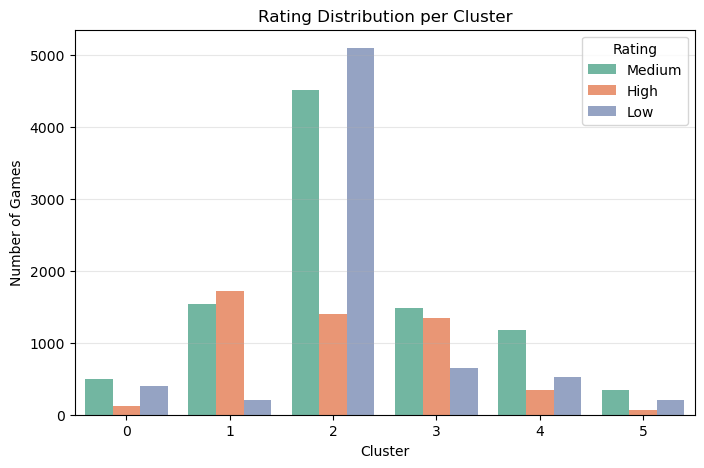

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Cluster_K6",
    hue="Rating",
    palette="Set2"
)
plt.title("Rating Distribution per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Games")
plt.legend(title="Rating")
plt.grid(axis="y", alpha=0.3)
plt.show()

The distribution of ratings in games per cluster reveals that the clusters identified by K-Means are not random with respect to ratings, but instead capture distinct profiles:
- Cluster 1 stands out as the highest-quality cluster, with nearly 50% high-rated games and the lowest proportion of low-rated games
- Clusters 2 and 0 are dominated by low-rated games, indicating clusters of generally less successful or less well-received games
- Clusters 4 and 5 show a strong concentration of medium-rated games, suggesting more balanced or mainstream game profiles
- Cluster 3 occupies an intermediate position, with a relatively even mix of medium and high ratings

Although ratings were not used as clustering features, the resulting clusters display clear rating stratification, indicating that the clustering captures meaningful structural differences in the data.

### 2. Rating proportions per cluster (mean)
Within each cluster, what percentage of games are high, low, or medium?

In [15]:
rating_proportions = (
    df.groupby("Cluster_K6")["Rating"]
      .value_counts(normalize=True)
      .unstack()
      .round(3)
)

rating_proportions

Rating,High,Low,Medium
Cluster_K6,,,
0,0.116,0.398,0.486
1,0.497,0.058,0.445
2,0.127,0.463,0.410
3,0.388,0.185,0.426
4,0.169,0.256,0.575
5,0.114,0.333,0.553


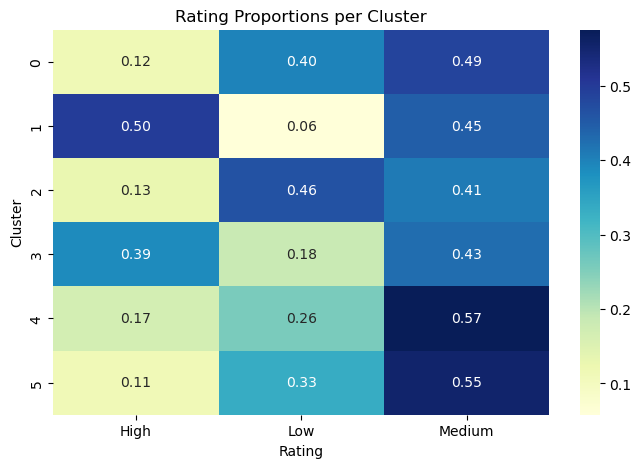

In [16]:
plt.figure(figsize=(8,5))
sns.heatmap(
    rating_proportions,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)
plt.title("Rating Proportions per Cluster")
plt.xlabel("Rating")
plt.ylabel("Cluster")
plt.show()

### 3. PCA visualization colored by Rating (NOT by cluster)
Does the structure discovered by PCA align with rating?

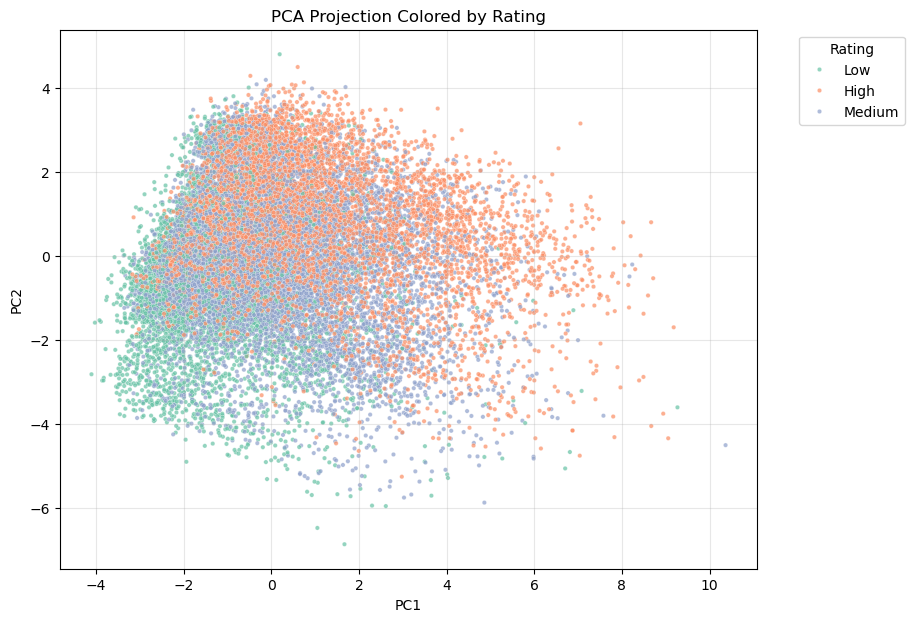

In [17]:
plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df,
    x="PC1",
    y="PC2",
    hue="Rating",
    palette="Set2",
    s=10,
    alpha=0.7
)
plt.title("PCA Projection Colored by Rating")
plt.legend(title="Rating", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

The PCA visualization (used ONLY for interpretation, not clustering) shows that:
- High-rated games tend to concentrate in specific regions of the projected feature space
- Low-rated games are more dispersed and occupy different areas than high-rated ones
- There is overlap, which is expected given the complexity of game characteristics, but the global trend aligns with cluster-level rating differences

This confirms that ratings are correlated with the underlying structure of the feature space and that the clustering captures latent dimensions related to perceived game quality, popularity, and complexity

**note**
clustering performed before PCA, in line with lectures

### 4. Rating vs cluster centroid profiles
linking cluster characteristics to rating outcomes

In [18]:
rating_map = {"Low": 1, "Medium": 2, "High": 3}
df["Rating_num"] = df["Rating"].map(rating_map)

mean_rating_per_cluster = df.groupby("Cluster_K6")["Rating_num"].mean()
mean_rating_per_cluster

Cluster_K6
0    1.718254
1    2.438257
2    1.664062
3    2.203282
4    1.912745
5    1.780449
Name: Rating_num, dtype: float64

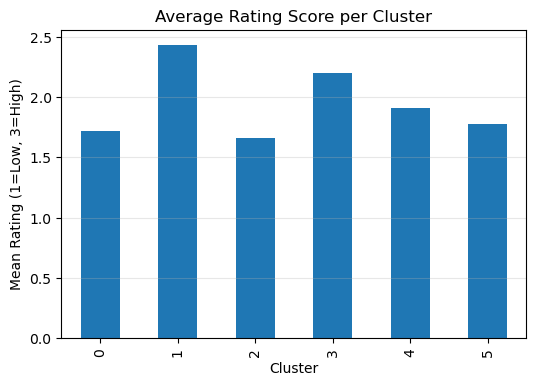

In [19]:
plt.figure(figsize=(6,4))
mean_rating_per_cluster.plot(kind="bar")
plt.title("Average Rating Score per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Mean Rating (1=Low, 3=High)")
plt.grid(axis="y", alpha=0.3)
plt.show

When ratings are mapped to numeric values (low = 1, medium = 2, high = 3), the average rating per cluster confirms this:
- Cluster 1 has the highest mean rating (2.44), reinforcing its interpretation as a cluster of high-quality, well-received games
- Cluster 3 follows, suggesting a group of strong but not elite games
- Clusters 0 and 2 have the lowest average ratings (1.66–1.72), aligning with their higher proportion of low-rated games
- Clusters 4 and 5 lie between these extremes, consistent with their dominance of medium ratings

The clusters are ordered along a quality gradient, from low-rated to high-rated games, without explicitly optimizing for ratings

By combining centroid information with rating outcomes:

- High-rated clusters (especially Cluster 1) are associated with higher popularity (NumOwned, NumInterest), moderate-to-high complexity (GameWeight), more modern publication years
- Low-rated clusters tend to correspond to lower engagement, less strategic depth or niche appeal, and older or less refined game designs

This suggests that player engagement, perceived complexity, and modern design trends are strongly linked to higher ratings

## Final Note
The rating-based analyses confirm that the clustering identifies distinct groups of board games that differ systematically in perceived quality. Even though ratings were excluded from the clustering process, they are a strong external validation signal, reinforcing the robustness and interpretability of the clustering results.

In [20]:
df_kmeans_export = df.copy()
df_kmeans_export[["BGGId", "Cluster_K6"]].to_csv(
    "kmeans_labels.csv", index=False
)